# GRADIEND: positive vs negative sentiment

In the [quickstart](https://github.com/aieng-lab/gradiend/blob/main/gradiend/examples/demo/01_quickstart_english_pronouns.ipynb) each class is a handful of words: *he, she, it* vs *they*. Sentiment has no such word list; any word can carry it.
We therefore use **adjectives as a proxy**: the ten most frequent positive and the ten most frequent negative adjectives in tweets (polarity from the NRC Emotion Lexicon).
To test that GRADIEND learned *sentiment* and not these twenty words, we **hold out whole adjectives**: 6 per class for training, 2 for validation, 2 for testing.

```
pip install gradiend[recommended]
```

In [1]:
import sys

if "google.colab" in sys.modules:  # on Colab: install the package first
    !pip install -q "gradiend[recommended]"

In [2]:
import transformers

transformers.logging.set_verbosity_error()  # quiet model-loading messages

MODEL = "bert-base-cased"  # any masked language model, e.g. "distilbert-base-cased" or "roberta-base"

## 1. Data

The creator finds the adjectives in tweets (`cardiffnlp/tweet_eval`) and masks them. `spacy_tags` keeps only matches that spaCy tags as adjectives (not *top* as a noun or *late* as an adverb), and `use_lemma=True` also matches inflected forms.
`balance="strict"` gives every adjective a similar number of rows (frequent words like *good* would otherwise dominate).
Unlike in the quickstart there is no fixed word pair, so the trainer picks the alternative of a row from the other class itself.
The result is published as `aieng-lab/en-sentiment-nrc`.

In [3]:
from gradiend import TextFilterConfig, TextPredictionDataCreator

positive = ["good", "great", "happy", "beautiful", "cool", "real", "true", "full", "top", "excited"]
negative = ["bad", "fake", "less", "mad", "stupid", "tired", "wrong", "late", "crazy", "sick"]

adjective = {"pos": "ADJ"}
creator = TextPredictionDataCreator(
    base_data="cardiffnlp/tweet_eval", hf_config="sentiment", spacy_model="en_core_web_sm",  # the spaCy model is downloaded on first use
    feature_targets=[
        TextFilterConfig(id="positive", targets=positive, spacy_tags=adjective, use_lemma=True),
        TextFilterConfig(id="negative", targets=negative, spacy_tags=adjective, use_lemma=True),
    ],
)
data = creator.generate_training_data(max_size_per_class=500, balance="strict", min_rows_per_target_for_balance=30, format="unified")
neutral = creator.generate_neutral_data(max_size=1000)

data[["masked", "label_class", "label"]].head(3)

2026-10-19 16:13:45 - WARNING - Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.


2026-10-19 16:13:59 - INFO -   positive: 500/500 matches (4.28% of sentences scanned)


2026-10-19 16:13:59 - INFO -   negative: 500/500 matches (1.44% of sentences scanned)


2026-10-19 16:13:59 - INFO - Overall: 1000/1000 (100.0%)


2026-10-19 16:13:59 - INFO - Training filter stats (instances per group): {'positive': 500, 'negative': 500}


2026-10-19 16:13:59 - INFO - Match rate per class (fraction of sentences scanned): {'positive': '4.28%', 'negative': '1.44%'}


2026-10-19 16:13:59 - INFO -   positive: strict per-label balance 500 -> 300 rows (10 distinct labels, min_rows_per_target=30)


2026-10-19 16:13:59 - INFO -   negative: strict per-label balance 500 -> 300 rows (10 distinct labels, min_rows_per_target=30)


2026-10-19 16:13:59 - INFO - Neutral filter stats: {'kept': 1000, 'excluded': 156, 'total': 1156} (success rate: 0.87)


,masked,label_class,label
0,Guess that just makes the lifting Local rags d...,positive,real
1,Gonna have to DVR this Isner and Federer match...,positive,good
2,Watching The Kandi Factory with Viggle Mon | 3...,positive,real


## 2. Train

Same procedure as in the quickstart, with one difference: `split_col="heldout"` lets the trainer hold out whole adjectives (`split_ratios`: 6 of the 10 words per class for training, 2 for validation, 2 for testing).
The alternative of a row is a word of the same split, so validation and test words never reach the training gradients.

2026-10-19 16:14:00 - INFO - Seed 0: starting training with output_dir=runs/sentiment/positive_negative/seeds/seed_0


2026-10-19 16:14:00 - INFO - Inferred decoder eval targets for positive_negative: {'positive': ['excited', 'happy', 'full', 'real', 'top', 'true', 'great', 'beautiful', 'good', 'cool'], 'negative': ['bad', 'fake', 'stupid', 'wrong', 'late', 'tired', 'mad', 'sick', 'crazy', 'less']}


2026-10-19 16:14:01 - INFO - Excluded 5 non-backbone (head) parameter(s); names: ['cls.predictions.bias', 'cls.predictions.transform.dense.weight', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.LayerNorm.bias']


2026-10-19 16:14:01 - INFO - Set feature_class_encoding_direction: {'positive': 1, 'negative': -1}


2026-10-19 16:14:01 - INFO - Streaming pre-prune: collecting top-10,771,968 over 107,719,680 input dimensions from 16 sample(s).


...

2026-10-19 16:15:08 - INFO - Selected best seed=0 -> runs/sentiment/positive_negative/model


2026-10-19 16:15:08 - INFO - Wrote full training stats to runs/sentiment/positive_negative/model/training.json


2026-10-19 16:15:08 - INFO - Saved convergence plot: runs/sentiment/positive_negative/training_convergence.png


2026-10-19 16:15:08 - INFO - Saved training convergence plot: runs/sentiment/positive_negative/training_convergence.png


2026-10-19 16:15:08 - INFO - Saved convergence plot: runs/sentiment/positive_negative/training_convergence.png


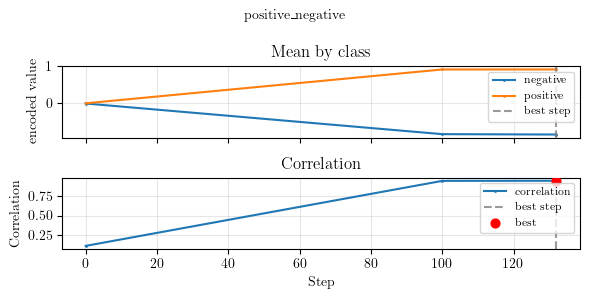

'runs/sentiment/positive_negative/training_convergence.png'

In [4]:
from gradiend import PostPruneConfig, PrePruneConfig, TextPredictionTrainer, TrainingArguments

args = TrainingArguments(
    experiment_dir="runs/sentiment", learning_rate=1e-4, train_batch_size=8, max_steps=500, eval_steps=100,
    max_seeds=3, min_convergent_seeds=1,
    pre_prune_config=PrePruneConfig(n_samples=16, topk=0.1), post_prune_config=PostPruneConfig(topk=0.001),
)
trainer = TextPredictionTrainer(
    model=MODEL, run_id="positive_negative", data=data, target_classes=["positive", "negative"], eval_neutral_data=neutral,
    split_col="heldout", split_ratios=(0.6, 0.2, 0.2), args=args,
)
trainer.train()
trainer.plot_training_convergence()

The adjectives of each split:

In [5]:
trainer.combined_data.groupby(["factual_class", "split"])["factual"].agg(lambda words: sorted(set(words.str.lower()))).unstack()

split,test,train,validation
factual_class,,,
negative,"[late, tired]","[bad, crazy, fake, mad, stupid, wrong]","[less, sick]"
positive,"[real, top]","[cool, excited, full, good, happy, true]","[beautiful, great]"


## 3. Held-out words

Every dot is one example, grouped by the masked adjective and coloured by split. The validation and test adjectives were never used for training. Most of them are still encoded on the correct side, with more spread than the training words:
GRADIEND learned a polarity that carries over to new words, not just these twenty.

2026-10-19 16:15:09 - INFO - Inferred decoder eval targets for positive_negative: {'positive': ['excited', 'happy', 'full', 'real', 'top', 'true', 'great', 'beautiful', 'good', 'cool'], 'negative': ['bad', 'fake', 'stupid', 'wrong', 'late', 'tired', 'mad', 'sick', 'crazy', 'less']}


2026-10-19 16:15:09 - INFO - Recomputing encoder analysis; existing cache will be overwritten after successful recomputation: runs/sentiment/positive_negative/encoded_values_split_train_validation_test.csv


2026-10-19 16:15:09 - INFO - Computing encoder analysis for all variants


2026-10-19 16:15:09 - INFO - Encoding training data (max_size=None, source=alternative, size=600)


2026-10-19 16:15:24 - INFO - Encoding neutral training masked data (max_size=None, size=120)


2026-10-19 16:15:30 - INFO - Encoding neutral dataset data (size=1000)


2026-10-19 16:15:51 - INFO - Saved encoder analysis results to runs/sentiment/positive_negative/encoded_values_split_train_validation_test.csv


2026-10-19 16:15:51 - INFO - Saved encoder by-target plot: runs/sentiment/positive_negative/encoder_analysis_by_target_strip.png


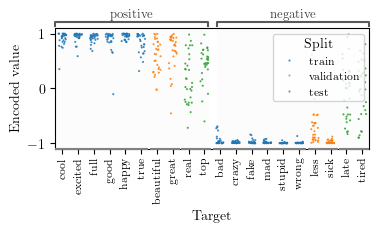

'runs/sentiment/positive_negative/encoder_analysis_by_target_strip.png'

In [6]:
enc = trainer.evaluate_encoder(split="all", max_size=None, return_df=True, plot=False)
trainer.plot_encoder_by_target(encoder_df=enc["encoder_df"], plot_style="strip")

## 4. Rewrite the model

As in the quickstart, the decoder strength trades the change in the model's predictions against the language modelling score (LMS).
Here we strengthen the *positive* direction and compare what the model predicts for neutral sentences.

2026-10-19 16:15:51 - INFO - Starting decoder evaluation with part=decoder


2026-10-19 16:15:51 - INFO - Decoder eval feature_factors=[1.0] class_to_ff={'positive': 1.0, 'negative': -1.0} source=alternative


2026-10-19 16:19:18 - INFO - Saved probability shifts plot to runs/sentiment/positive_negative/positive_negative/decoder_probability_shifts_positive.png


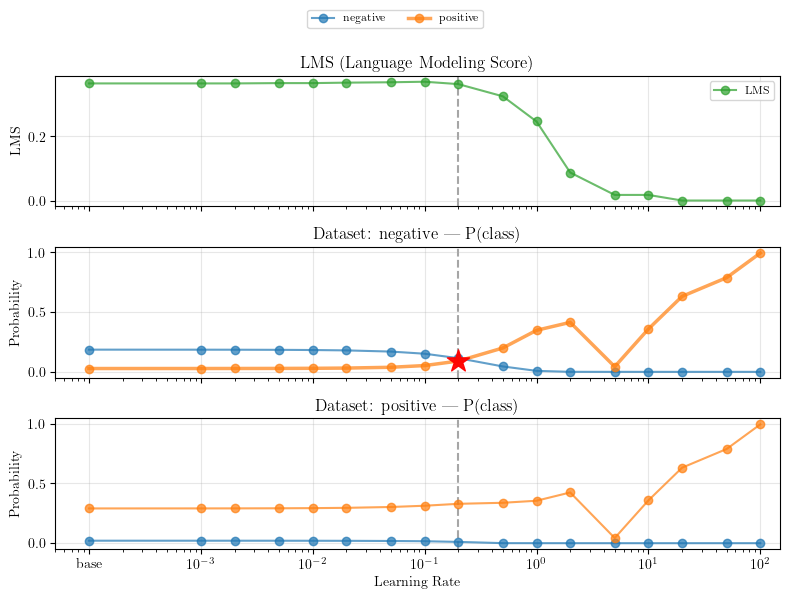

In [7]:
dec = trainer.evaluate_decoder(plot=True, target_class="positive")
changed_model = trainer.rewrite_base_model(decoder_results=dec, target_class="positive")

In [8]:
from transformers import AutoModelForMaskedLM, AutoTokenizer, pipeline

tokenizer = AutoTokenizer.from_pretrained(MODEL)
mask = tokenizer.mask_token
for name, model in [("base", AutoModelForMaskedLM.from_pretrained(MODEL)), ("rewritten (positive)", changed_model)]:
    fill = pipeline("fill-mask", model=model, tokenizer=tokenizer)
    for text in [f"The movie was really {mask}.", f"My day was {mask}."]:
        print(name, "|", text, [(r["token_str"], round(r["score"], 3)) for r in fill(text, top_k=5)])

base | The movie was really [MASK]. [('good', 0.302), ('great', 0.066), ('cool', 0.036), ('awesome', 0.036), ('fun', 0.035)]
base | My day was [MASK]. [('over', 0.185), ('done', 0.102), ('perfect', 0.045), ('finished', 0.025), ('complete', 0.022)]
rewritten (positive) | The movie was really [MASK]. [('good', 0.452), ('great', 0.092), ('fun', 0.047), ('exciting', 0.038), ('interesting', 0.033)]
rewritten (positive) | My day was [MASK]. [('over', 0.088), ('done', 0.062), ('complete', 0.051), ('good', 0.049), ('perfect', 0.046)]
